In [1]:
import pandas as pd
import os
from skimage.transform import resize
from skimage.io import imread
import numpy as np
import matplotlib.pyplot as plt
from skimage import io, transform
from sklearn import preprocessing
import numpy as np
import joblib
import cv2
from sklearn import svm
from sklearn.naive_bayes import GaussianNB, MultinomialNB, BernoulliNB
from sklearn.datasets import load_iris
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier,VotingClassifier


In [2]:
path = r"C:\Users\Srinitha\OneDrive\Desktop\mini project\Meat freshness"
model_folder = "model"
categories = [d for d in os.listdir(path) if os.path.isdir(os.path.join(path, d))]
categories

['FRESH', 'SPOILED']

In [3]:
X_file = os.path.join(model_folder,"X.txt.npy")
Y_file = os.path.join(model_folder,"Y.txt.npy")
if os.path.exists(X_file) and os.path.exists(Y_file):
    X = np.load(X_file)
    Y = np.load(Y_file)
    print("X and Y arrays loaded successfully.")
else:
    X = [] # input array
    Y = [] # output array
    for root, dirs, directory in os.walk(path):
        for j in range(len(directory)):
            name = os.path.basename(root)
            print(f'Loading category: {dirs}')
            print(name+" "+root+"/"+directory[j])
            if 'Thumbs.db' not in directory[j]:
                img_array = cv2.imread(root+"/"+directory[j])
                img_resized = resize(img_array, (64, 64, 3))
                X.append(img_resized.flatten())
                Y.append(categories.index(name))
    X = np.array(X)
    Y = np.array(Y)
    
    np.save(X_file, X)
    np.save(Y_file, Y)
                   


X and Y arrays loaded successfully.


In [4]:
df=pd.DataFrame(X)
df

,0,1,2,3,4,5,6,7,8,9,...,12278,12279,12280,12281,12282,12283,12284,12285,12286,12287
0,0.596087,0.674412,0.906265,0.542277,0.603143,0.858254,0.614208,0.686067,0.893549,0.648331,...,0.249142,0.253813,0.273905,0.271170,0.285233,0.305325,0.302589,0.295733,0.315825,0.313089
1,0.596087,0.674412,0.906265,0.542277,0.603143,0.858254,0.614208,0.686067,0.893549,0.648331,...,0.249142,0.253813,0.273905,0.271170,0.285233,0.305325,0.302589,0.295733,0.315825,0.313089
2,0.721512,0.760728,0.827395,0.719844,0.758966,0.825633,0.727051,0.763258,0.829896,0.725302,...,0.777012,0.517218,0.537290,0.706140,0.362488,0.380645,0.578683,0.362058,0.397582,0.582639
3,0.425374,0.431245,0.570155,0.445711,0.442533,0.570944,0.514356,0.500038,0.607160,0.475348,...,0.447783,0.420424,0.433895,0.452752,0.426598,0.452272,0.465142,0.514646,0.533051,0.504968
4,0.736333,0.870805,0.917846,0.713888,0.847353,0.897811,0.645762,0.771918,0.860335,0.586608,...,0.708491,0.432279,0.554110,0.740878,0.443216,0.544046,0.753321,0.315337,0.391621,0.635295
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1355,0.134959,0.228414,0.345352,0.143670,0.236992,0.353984,0.144454,0.231959,0.351370,0.149177,...,0.223744,0.142908,0.186417,0.241535,0.104166,0.172864,0.274383,0.050760,0.146220,0.287056
1356,0.116363,0.207193,0.331357,0.127970,0.221975,0.335329,0.161806,0.256089,0.328473,0.200971,...,0.390833,0.078433,0.211961,0.385970,0.059203,0.182656,0.352739,0.071988,0.187558,0.344083
1357,0.153834,0.247952,0.389128,0.150741,0.244681,0.385810,0.160479,0.248394,0.387560,0.154660,...,0.364189,0.132865,0.229403,0.374459,0.122098,0.223922,0.369056,0.117657,0.219618,0.364716
1358,0.179768,0.263714,0.435235,0.181424,0.268488,0.427985,0.168575,0.260545,0.406277,0.156697,...,0.523777,0.588098,0.578999,0.528272,0.473702,0.452707,0.394890,0.691609,0.657198,0.614901


In [5]:
df['labels']=Y
Y

array([0, 0, 0, ..., 1, 1, 1])

In [6]:
x_train,x_test,y_train,y_test=train_test_split(X,Y,test_size=0.20,random_state=77)


In [7]:
accuracy=[]
precision = []
recall = []
fscore = []
overall_results = []

classwise_results = []

In [8]:
def calculateMetrics(algorithm, predict, testY, labels):

    a = accuracy_score(testY, predict) * 100
    p = precision_score(testY, predict, average='macro') * 100
    r = recall_score(testY, predict, average='macro') * 100
    f = f1_score(testY, predict, average='macro') * 100

    overall_results.append({
        "Algorithm": algorithm,
        "Accuracy (%)": a,
        "Precision (%)": p,
        "Recall (%)": r,
        "F1 Score (%)": f
    })

    print(f"{algorithm} Accuracy: {a:.2f}")
    print(f"{algorithm} Precision: {p:.2f}")
    print(f"{algorithm} Recall: {r:.2f}")
    print(f"{algorithm} F1 Score: {f:.2f}\n")

    report = classification_report(testY, predict, target_names=labels, output_dict=True)
    conf_matrix = confusion_matrix(testY, predict)

    class_accuracy = conf_matrix.diagonal() / conf_matrix.sum(axis=1)

    print(f"{algorithm} Class-wise Metrics:")
    print(f"{'Class':<12}{'Accuracy':<12}{'Precision':<12}{'Recall':<12}{'F1 Score':<12}")

    for i, class_name in enumerate(labels):
        acc = class_accuracy[i] * 100
        prec = report[class_name]['precision'] * 100
        rec = report[class_name]['recall'] * 100
        f1 = report[class_name]['f1-score'] * 100

        print(f"{class_name:<12}{acc:<12.2f}{prec:<12.2f}{rec:<12.2f}{f1:<12.2f}")

        classwise_results.append({
            "Algorithm": algorithm,
            "Class": class_name,
            "Accuracy (%)": acc,
            "Precision (%)": prec,
            "Recall (%)": rec,
            "F1 Score (%)": f1
        })

    plt.figure(figsize=(5, 5))
    sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues",
                xticklabels=labels, yticklabels=labels)
    plt.title(f"{algorithm} Confusion Matrix")
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')
    plt.show()

Multinomial NBC Accuracy: 76.84
Multinomial NBC Precision: 77.23
Multinomial NBC Recall: 76.45
Multinomial NBC F1 Score: 76.53

Multinomial NBC Class-wise Metrics:
Class       Accuracy    Precision   Recall      F1 Score    
FRESH       83.92       75.00       83.92       79.21       
SPOILED     68.99       79.46       68.99       73.86       


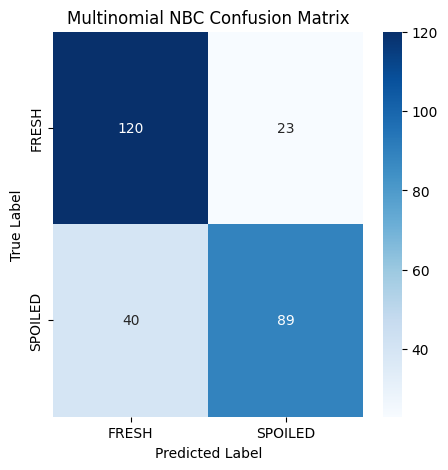

In [9]:
Model_file = os.path.join(model_folder, "Multi_NBC_Model.pkl")
if os.path.exists(Model_file):
    nb_classifier = joblib.load(Model_file)
    y_pred = nb_classifier.predict(x_test)
    calculateMetrics("Multinomial NBC", y_pred, y_test, categories)
else:
    nb_classifier = MultinomialNB()
    nb_classifier.fit(x_train, y_train)
    joblib.dump(nb_classifier, Model_file)  
    y_pred = nb_classifier.predict(x_test)
    calculateMetrics("Multinomial NBC", y_pred, y_test, categories)

DTC Accuracy: 84.93
DTC Precision: 85.03
DTC Recall: 85.10
DTC F1 Score: 84.92

DTC Class-wise Metrics:
Class       Accuracy    Precision   Recall      F1 Score    
FRESH       81.82       88.64       81.82       85.09       
SPOILED     88.37       81.43       88.37       84.76       


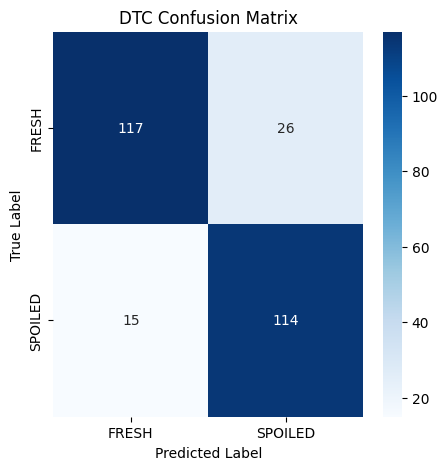

In [10]:
Model_file = os.path.join(model_folder, "DTC_Model.pkl")
if os.path.exists(Model_file):
    dt_classifier = joblib.load(Model_file)
    y_pred = dt_classifier.predict(x_test)
    calculateMetrics("DTC", y_pred, y_test, categories)
else:
    dt_classifier = DecisionTreeClassifier()
    dt_classifier.fit(x_train, y_train)
    joblib.dump(dt_classifier, Model_file)  
    y_pred = dt_classifier.predict(x_test)
    calculateMetrics("DTC", y_pred, y_test, categories)

Extra Trees Accuracy: 93.75
Extra Trees Precision: 93.80
Extra Trees Recall: 93.68
Extra Trees F1 Score: 93.73

Extra Trees Class-wise Metrics:
Class       Accuracy    Precision   Recall      F1 Score    
FRESH       95.10       93.15       95.10       94.12       
SPOILED     92.25       94.44       92.25       93.33       


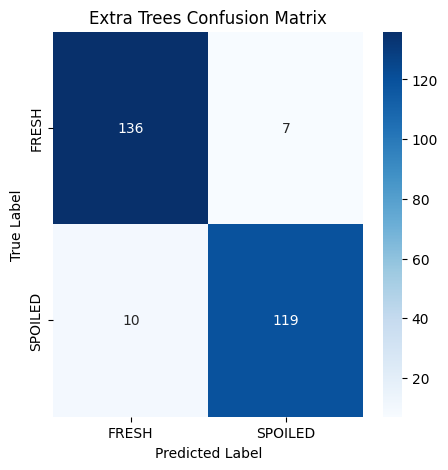

In [11]:
Model_file = os.path.join(model_folder, "EX_Model.pkl")
if os.path.exists(Model_file):
    ex_classifier = joblib.load(Model_file)
    y_pred = ex_classifier.predict(x_test)
    calculateMetrics("Extra Trees", y_pred, y_test, categories)
else:
    ex_classifier = ExtraTreesClassifier()
    ex_classifier.fit(x_train, y_train)
    joblib.dump(ex_classifier, Model_file)  
    y_pred = ex_classifier.predict(x_test)
    calculateMetrics("Extra Trees", y_pred, y_test, categories)

In [12]:
overall_df = pd.DataFrame(overall_results)
overall_df


,Algorithm,Accuracy (%),Precision (%),Recall (%),F1 Score (%)
0,Multinomial NBC,76.838235,77.232143,76.454166,76.533421
1,DTC,84.926471,85.032468,85.095137,84.924637
2,Extra Trees,93.750000,93.797565,93.676479,93.725490


In [13]:
classwise_df = pd.DataFrame(classwise_results)
classwise_df


,Algorithm,Class,Accuracy (%),Precision (%),Recall (%),F1 Score (%)
0,Multinomial NBC,FRESH,83.916084,75.000000,83.916084,79.207921
1,Multinomial NBC,SPOILED,68.992248,79.464286,68.992248,73.858921
2,DTC,FRESH,81.818182,88.636364,81.818182,85.090909
3,DTC,SPOILED,88.372093,81.428571,88.372093,84.758364
4,Extra Trees,FRESH,95.104895,93.150685,95.104895,94.117647
5,Extra Trees,SPOILED,92.248062,94.444444,92.248062,93.333333


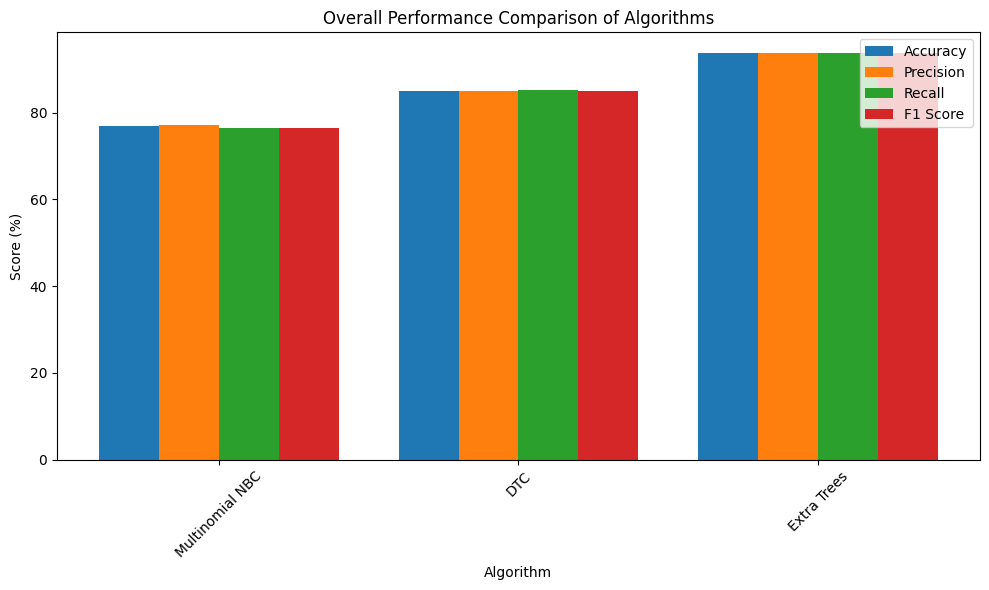

In [14]:
import numpy as np

# X locations
x = np.arange(len(overall_df['Algorithm']))
width = 0.2

plt.figure(figsize=(10,6))

plt.bar(x - 1.5*width, overall_df['Accuracy (%)'], width, label='Accuracy')
plt.bar(x - 0.5*width, overall_df['Precision (%)'], width, label='Precision')
plt.bar(x + 0.5*width, overall_df['Recall (%)'], width, label='Recall')
plt.bar(x + 1.5*width, overall_df['F1 Score (%)'], width, label='F1 Score')

plt.xticks(x, overall_df['Algorithm'], rotation=45)
plt.xlabel("Algorithm")
plt.ylabel("Score (%)")
plt.title("Overall Performance Comparison of Algorithms")
plt.legend()
plt.tight_layout()
plt.show()


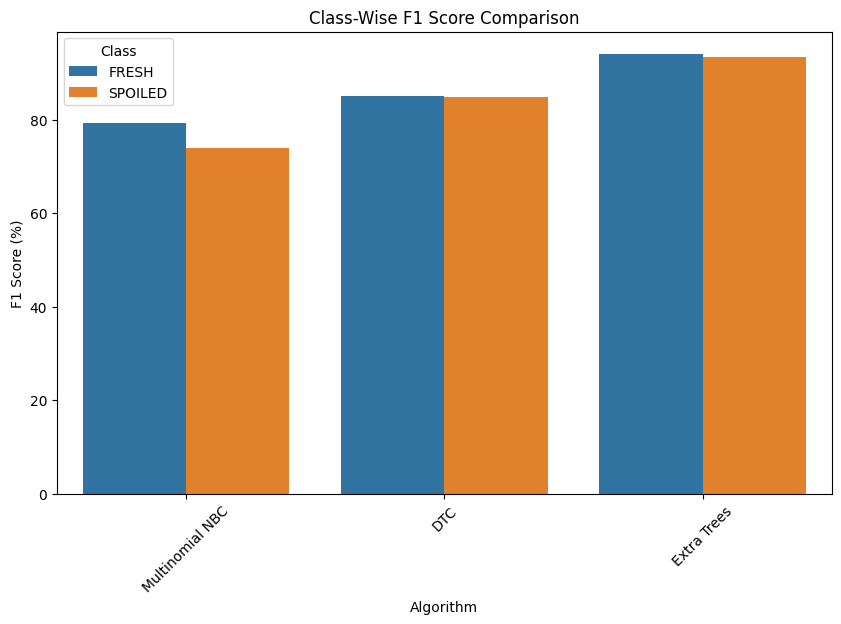

In [15]:
plt.figure(figsize=(10,6))
sns.barplot(
    data=classwise_df,
    x="Algorithm",
    y="F1 Score (%)",
    hue="Class"
)
plt.title("Class-Wise F1 Score Comparison")
plt.xlabel("Algorithm")
plt.ylabel("F1 Score (%)")
plt.xticks(rotation=45)
plt.legend(title="Class")
plt.show()


Gaussian NBC Accuracy: 87.13
Gaussian NBC Precision: 87.19
Gaussian NBC Recall: 87.00
Gaussian NBC F1 Score: 87.07

Gaussian NBC Class-wise Metrics:
Class       Accuracy    Precision   Recall      F1 Score    
FRESH       89.51       86.49       89.51       87.97       
SPOILED     84.50       87.90       84.50       86.17       


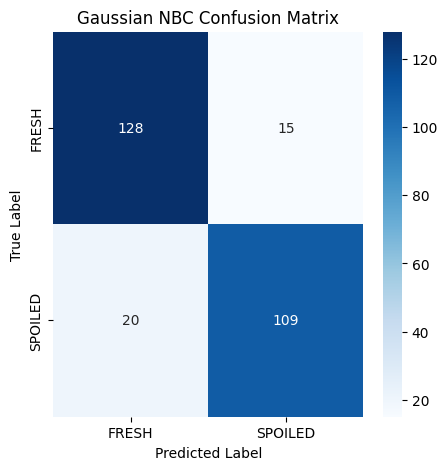

In [16]:
Model_file = os.path.join(model_folder, "Gaussian_NBC_Model.pkl")
if os.path.exists(Model_file):
    nb_classifier = joblib.load(Model_file)
    y_pred = nb_classifier.predict(x_test)
    calculateMetrics("Gaussian NBC", y_pred, y_test, categories)
else:
    nb_classifier = GaussianNB()
    nb_classifier.fit(x_train, y_train)
    joblib.dump(nb_classifier, Model_file)  
    y_pred = nb_classifier.predict(x_test)
    calculateMetrics("Gaussian NBC", y_pred, y_test, categories)

Extra Trees Accuracy: 93.75
Extra Trees Precision: 93.80
Extra Trees Recall: 93.68
Extra Trees F1 Score: 93.73

Extra Trees Class-wise Metrics:
Class       Accuracy    Precision   Recall      F1 Score    
FRESH       95.10       93.15       95.10       94.12       
SPOILED     92.25       94.44       92.25       93.33       


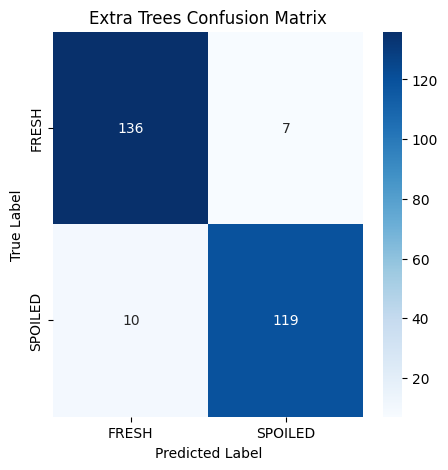

In [17]:
Model_file = os.path.join(model_folder, "EX_Model.pkl")
if os.path.exists(Model_file):
    ex_classifier = joblib.load(Model_file)
    y_pred = ex_classifier.predict(x_test)
    calculateMetrics("Extra Trees", y_pred, y_test, categories)
else:
    ex_classifier = ExtraTreesClassifier()
    ex_classifier.fit(x_train, y_train)
    joblib.dump(ex_classifier, Model_file)  
    y_pred = ex_classifier.predict(x_test)
    calculateMetrics("Extra Trees", y_pred, y_test, categories)

In [1]:
# Check if the pkl file exists
Model_file = os.path.join(model_folder, "Random Forest Classifier_Model.pkl")
if os.path.exists(Model_file):
    rf_classifier = joblib.load(Model_file)
    y_pred = rf_classifier.predict(x_test)
    calculateMetrics("RFC", y_pred, y_test, categories)
else:
    rf_classifier = RandomForestClassifier()
    rf_classifier.fit(x_train, y_train)
    joblib.dump(rf_classifier, Model_file)  
    y_pred = rf_classifier.predict(x_test)
    calculateMetrics("RFC", y_pred, y_test, categories)

NameError: name 'os' is not defined